In [24]:
import torch
from d2l import torch as d2l
from torch import nn
import torch.nn.functional as F

In [ ]:
#序列模型
#序列数据不同于图像，具有连续性（重排会失去意义）、时空相关性（相近的一段序列内容相关）、外推法（预测）比内插法（估计）更难
#通常的序列数据建模为以time step为基础的离散序列，‘预测’的定义为xt~P(xt|xt-1,...,x2,x1)
#词元化tokenize，将真实序列转换为以token为单元的离散序列

#马尔科夫模型：认为未来的状态只依赖于当前状态（可以理解为目前往前数固定长度tau的最近历史序列），与更早的历史无关。
#      马尔科夫条件：x表示一个时间步的状态，满足P(x1,x2,...,xT)=连乘(1~T)P(xt|xt-1)，且P(x1|x0)=P(x1)；一阶马尔科夫模型

#动力学静止假设：虽然序列的时间不会停滞，但可以假设推动序列前进的‘动力规则pattern’是不变的，是可学习的。

#能够实现预测的模型有两类：
# 1自回归模型（autoregressive），即认为序列以固定长度tau为时间跨度循环，每次只用一段序列的连续tau的小段预测下一个是time step，本次的预测结果会作为下一次预测的输入。
# 2隐变量自回归模型（latent）,认为x只是表面状态，无法表示当前的完整状态，实际还存在一个隐状态h，


In [36]:
batch_size=16
n_train=600
lr=0.01
num_epochs=5
tau=4
points=1000
net = nn.Sequential(nn.Linear(tau,10),nn.ReLU(),nn.Linear(10,1))
x=torch.arange(1,points+1,dtype=torch.float32)
T=torch.sin(x*0.01)+torch.normal(0,0.2,[points,])
features=torch.zeros((points-tau,tau),dtype=torch.float32)
for i in range(tau):
    features[:,i]=T[torch.arange(i,i+points-tau)]
labels=T[tau:].reshape((-1,1))

train_iter = d2l.load_array((features[:n_train], labels[:n_train]),  batch_size, is_train=True)

def init_weight(m):
    if type(m)==nn.Linear or type(m)==nn.Conv2d:
        nn.init.xavier_uniform_(m.weight)

net.apply(init_weight)

X = torch.rand(size=(4,)) 
for layer in net:
    X = layer(X) 
    print(layer.__class__.__name__,'output shape:\t', X.shape)

loss=nn.MSELoss()

updater=torch.optim.SGD(net.parameters(),lr=lr)


Linear output shape:	 torch.Size([10])
ReLU output shape:	 torch.Size([10])
Linear output shape:	 torch.Size([1])


In [37]:
def evaluate_accuracy_gpu(net, data_iter, device=None): #@save
    """使用GPU计算模型在数据集上的精度"""
    if isinstance(net, nn.Module):
        net.eval()  # 设置为评估模式
        if not device:
            device = next(iter(net.parameters())).device
    # 正确预测的数量，总预测的数量
    metric = d2l.Accumulator(2)
    with torch.no_grad():
        for X, y in data_iter:
            if isinstance(X, list):
                # BERT微调所需的（之后将介绍）
                X = [x.to(device) for x in X]
            else:
                X = X.to(device)
            y = y.to(device)
            metric.add(d2l.accuracy(net(X), y), y.numel())
    return metric[0] / metric[1]

In [38]:
def train_ch6(net, train_iter, test_iter, optimizer,loss,num_epochs, device):
    print('training on', device)
    net.to(device)
    animator = d2l.Animator(xlabel='epoch', xlim=[1, num_epochs],
                            legend=['train loss', 'train acc', 'test acc'])
    timer, num_batches = d2l.Timer(), len(train_iter)
    for epoch in range(num_epochs):
        # 训练损失之和，训练准确率之和，样本数
        metric = d2l.Accumulator(3)
        net.train()
        for i, (X, y) in enumerate(train_iter):
            timer.start()
            optimizer.zero_grad()
            X, y = X.to(device), y.to(device)
            y_hat = net(X)
            l = loss(y_hat, y)
            l.backward()
            optimizer.step()
            with torch.no_grad():
                metric.add(l * X.shape[0], d2l.accuracy(y_hat, y), X.shape[0])
            timer.stop()
            train_l = metric[0] / metric[2]
            train_acc = metric[1] / metric[2]
            if (i + 1) % (num_batches // 5) == 0 or i == num_batches - 1:
                animator.add(epoch + (i + 1) / num_batches,
                             (train_l, train_acc, None))
        test_acc = evaluate_accuracy_gpu(net, train_iter)
        animator.add(epoch + 1, (None, None, test_acc))
    print(f'loss {train_l:.3f}, train acc {train_acc:.3f}, '
          f'test acc {test_acc:.3f}')
    print(f'{metric[2] * num_epochs / timer.sum():.1f} examples/sec '
          f'on {str(device)}')

loss 0.059, train acc 0.000, test acc 0.000
26404.0 examples/sec on cpu


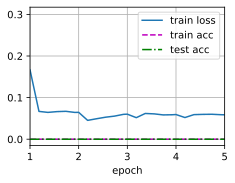

In [39]:
train_ch6(net,train_iter,None,updater,loss,num_epochs,torch.device('cpu'))

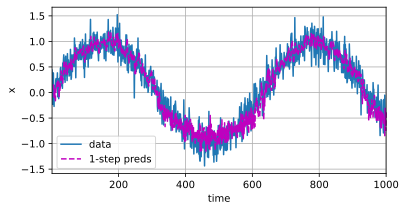

In [40]:
onestep_preds = net(features) 
d2l.plot([x, x[tau:]],
        [T.detach().numpy(),
          onestep_preds.detach().numpy()], 'time', 'x',
            legend=['data', '1-step preds'], xlim=[1, 1000], figsize=(6, 3))

In [ ]:
multistep_preds = torch.zeros(T) 
multistep_preds[: n_train + tau] = x[: n_train + tau] 
for i in range(n_train + tau, T):
      multistep_preds[i] = net(
          multistep_preds[i - tau:i].reshape((1, -1)))

In [ ]:
d2l.plot([x, x[tau:], T[n_train + tau:]],  [x.detach().numpy(), onestep_preds.detach().numpy(), multistep_preds[n_train + tau:].detach().numpy()], 'time', 'x', legend=['data', '1-step preds', 'multistep preds'], xlim=[1, 1000], figsize=(6, 3))